/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_25923/2219374046.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['number_of_stable_matchings'] = pd.to_numeric(df_filtered['number_of_stable_matchings'], errors='coerce')


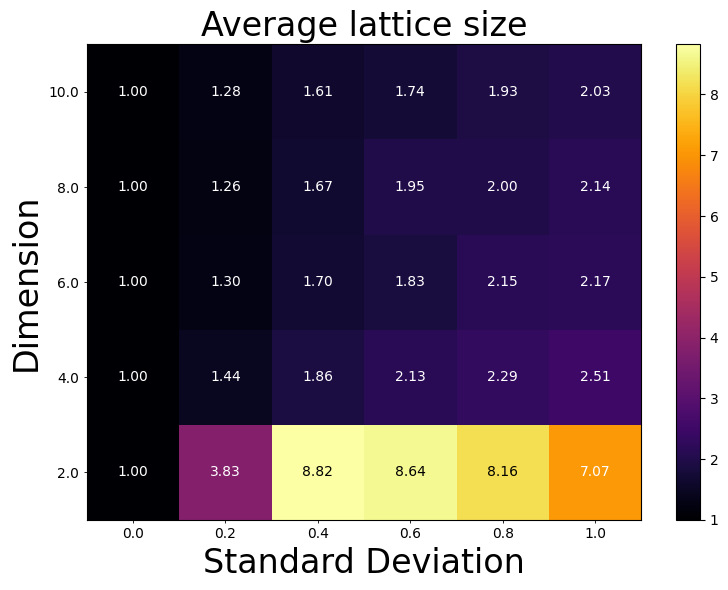

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("expectations_euclidean_accomplice.csv")

# Extract relevant columns
df_filtered = df[['dimension', 'std', 'number_of_stable_matchings']]

# Convert value column to numeric
df_filtered['number_of_stable_matchings'] = pd.to_numeric(df_filtered['number_of_stable_matchings'], errors='coerce')
df_filtered = df_filtered.dropna(subset=['number_of_stable_matchings'])

# Unique sorted phi values
phi1_vals = sorted(df_filtered['dimension'].unique())
phi2_vals = sorted(df_filtered['std'].unique())

# Pivot and reindex
pivot_table = df_filtered.pivot_table(index='dimension', columns='std', values='number_of_stable_matchings', aggfunc='mean')
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)
data_matrix = pivot_table.values

# Plotting
fig, ax = plt.subplots(figsize=(8, 6))
c = ax.pcolormesh(data_matrix, cmap='inferno', norm=mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))
fig.colorbar(c, ax=ax)

# Annotate cells
for i, phi_m in enumerate(phi1_vals):
    for j, phi_w in enumerate(phi2_vals):
        val = data_matrix[i, j]
        if not np.isnan(val):
            if (np.isclose(phi_m, 2.0) and np.isclose(phi_w, 0.4)) or (np.isclose(phi_m, 2.0) and np.isclose(phi_w, 0.6)) or (np.isclose(phi_m, 2.0) and np.isclose(phi_w, 0.8)):
                text_color = 'black'  # Special cell
            else:
                text_color = 'white'
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color=text_color)

# Ticks and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels
plt.xlabel('Standard Deviation', fontsize=24)
plt.ylabel('Dimension', fontsize=24)
plt.title('Average lattice size', fontsize=24)

# Save and show
plt.grid(True)
plt.tight_layout()
plt.savefig("expectations_euclidean_lattice.pdf", format='pdf')
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_66270/238342792.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['self_manipulating_women'] = pd.to_numeric(df_filtered['self_manipulating_women'], errors='coerce')


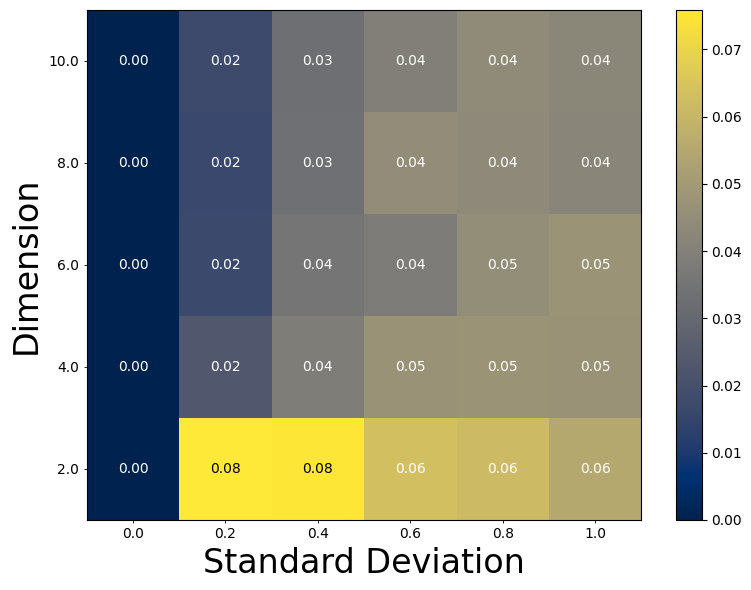

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("expectations_euclidean_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['dimension', 'std', 'self_manipulating_women']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['self_manipulating_women'] = pd.to_numeric(df_filtered['self_manipulating_women'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['self_manipulating_women'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['dimension'].unique())
phi2_vals = sorted(df_filtered['std'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='dimension', columns='std', values='self_manipulating_women', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

data_matrix = data_matrix / 30  # Scale down for better readability

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='cividis', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            if (i == 0 and j== 1) or (i == 0 and j == 2):
                text_color = 'black'  # Special cell
            else:
                text_color = 'white'
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color=text_color)

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel('Standard Deviation', fontsize=24)
plt.ylabel('Dimension', fontsize=24)
#plt.title('Self Manipulation', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("expectations_euclidean_self_30.pdf", format='pdf')
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_66270/395151664.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')


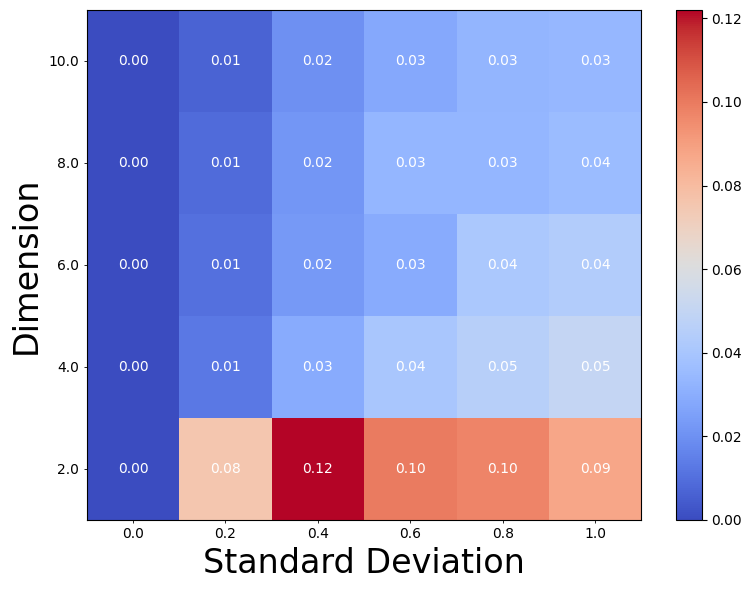

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("expectations_euclidean_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['dimension', 'std', 'count_woman']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_woman'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['dimension'].unique())
phi2_vals = sorted(df_filtered['std'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='dimension', columns='std', values='count_woman', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

data_matrix = data_matrix / 30  # Scale down for better readability

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='coolwarm', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel('Standard Deviation', fontsize=24)
plt.ylabel('Dimension', fontsize=24)
#plt.title('Accomplice: Beneficiary Women', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("expectations_euclidean_acc_women_30.pdf", format='pdf')
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_25923/3154506749.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['cnt_pairs'] = pd.to_numeric(df_filtered['cnt_pairs'], errors='coerce')


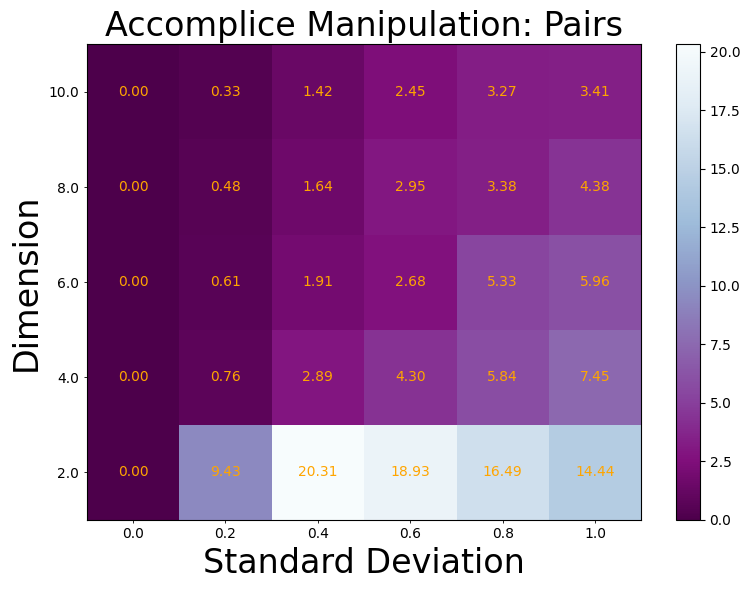

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("expectations_euclidean_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['dimension', 'std', 'cnt_pairs']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['cnt_pairs'] = pd.to_numeric(df_filtered['cnt_pairs'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['cnt_pairs'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['dimension'].unique())
phi2_vals = sorted(df_filtered['std'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='dimension', columns='std', values='cnt_pairs', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='BuPu_r', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='orange')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel('Standard Deviation', fontsize=24)
plt.ylabel('Dimension', fontsize=24)
plt.title('Accomplice Manipulation: Pairs', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("expectations_euclidean_acc_pairs.pdf", format='pdf')
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_25923/2491949039.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_men'] = pd.to_numeric(df_filtered['count_men'], errors='coerce')


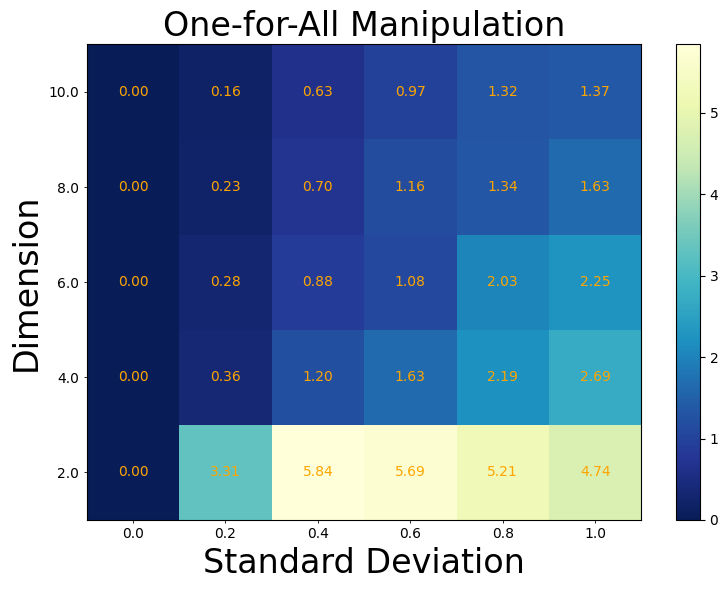

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("expectations_euclidean_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['dimension', 'std', 'count_men']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_men'] = pd.to_numeric(df_filtered['count_men'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_men'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['dimension'].unique())
phi2_vals = sorted(df_filtered['std'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='dimension', columns='std', values='count_men', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='YlGnBu_r', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='orange')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel('Standard Deviation', fontsize=24)
plt.ylabel('Dimension', fontsize=24)
plt.title('One-for-All Manipulation', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("expectations_euclidean_one_for_all.pdf", format='pdf')
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_66270/240966213.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')


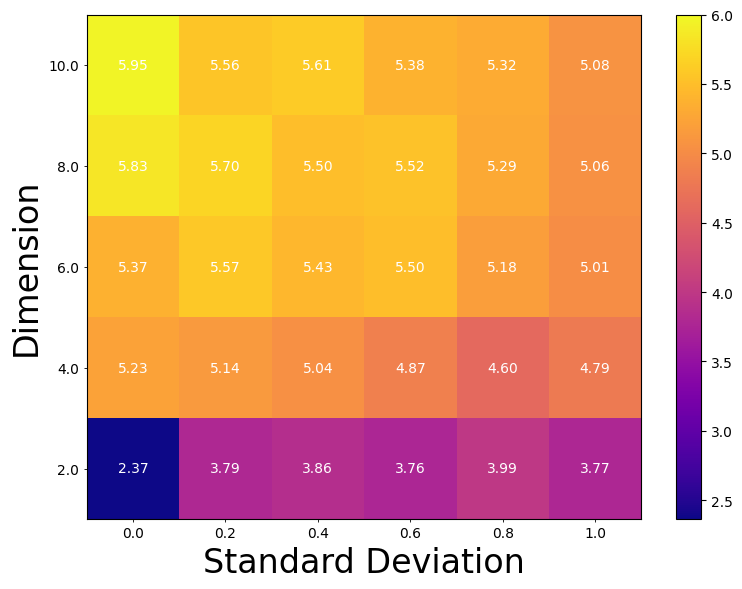

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("Expectations_Euclidean_two_for_one_results.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['Dimension', 'Std', 'Two_for_one']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['Two_for_one'])

# Get sorted unique values for heatmap axes
dim_vals = sorted(df_filtered['Dimension'].unique())
prop_vals = sorted(df_filtered['Std'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='Dimension', columns='Std', values='Two_for_one', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=dim_vals, columns=prop_vals)

# Convert to matrix
data_matrix = pivot_table.values

data_matrix = data_matrix /30

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='plasma', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=6))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')

# Tick positions and labels
ax.set_xticks(np.arange(len(prop_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(dim_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in prop_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in dim_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel('Standard Deviation', fontsize=24)
plt.ylabel('Dimension', fontsize=24)
#plt.title('One-for-All Manipulation', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("expectations_euclidean_two_for_one_30.pdf", format='pdf')
plt.show()


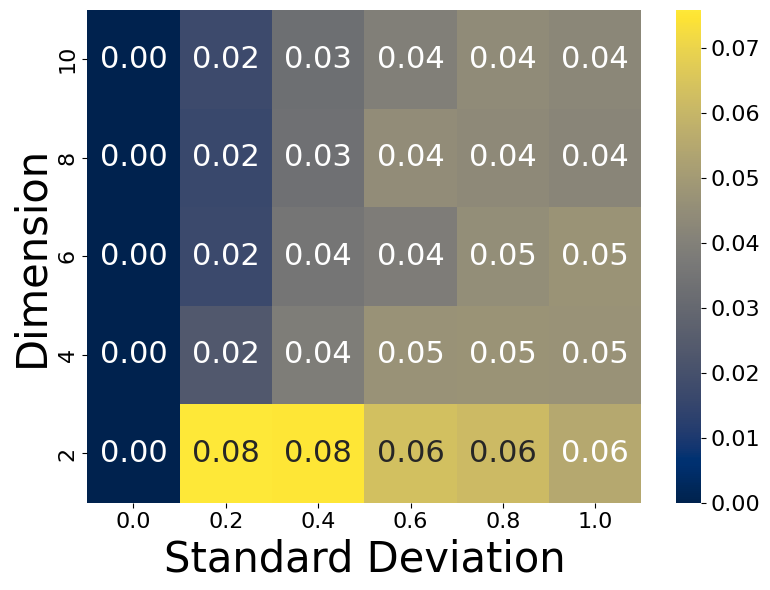

In [6]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_accomplice.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["self_manipulating_women"].mean().reset_index()

heatmap_data["self_manipulating_women"] = heatmap_data["self_manipulating_women"] / 30  # Scale down for better readability

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="self_manipulating_women")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Standard Deviation", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("expectations_euclidean_self_30.pdf", format="pdf")
plt.show()


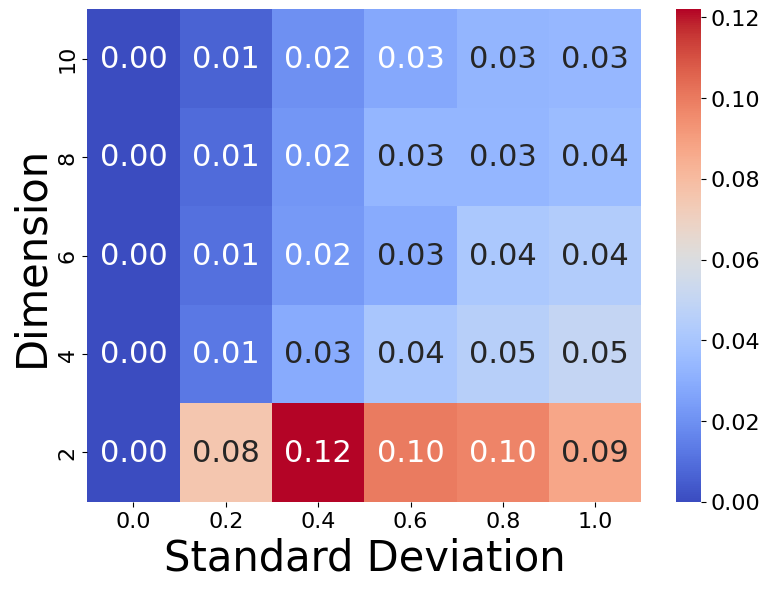

In [8]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_accomplice.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["count_woman"].mean().reset_index()

heatmap_data["count_woman"] = heatmap_data["count_woman"] / 30  # Scale down for better readability

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="count_woman")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Standard Deviation", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("expectations_euclidean_acc_women_30.pdf", format="pdf")
plt.show()


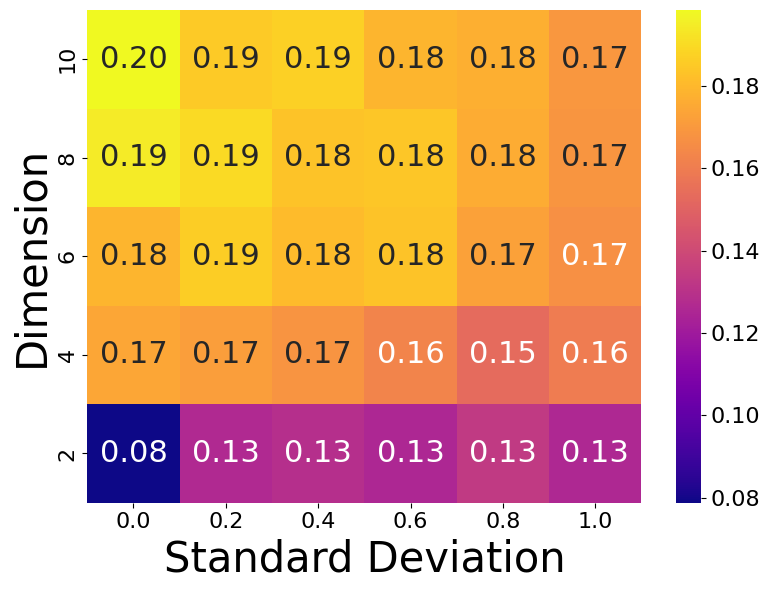

In [10]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("Expectations_Euclidean_two_for_one_results.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["Dimension", "Std"])["Two_for_one"].mean().reset_index()

heatmap_data["Two_for_one"] = heatmap_data["Two_for_one"] / 900  # Scale down for better readability

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="Dimension", columns="Std", values="Two_for_one")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Standard Deviation", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("expectations_euclidean_two_for_one_30.pdf", format="pdf")
plt.show()
